<a id="chapter-11"></a>

# Chapter 11 · Policy Gradients - an Alternative / 策略梯度

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 从最大化期望回报推导 REINFORCE
- 理解 baseline 不改变期望梯度
- 正确处理 log-prob、return 与 entropy

**开始前最好已经会：**

- 理解概率分布与期望
- 会求对数和链式法则
- 掌握 episode return


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Values and policy | 价值法与策略法对照 | 详细 |
| REINFORCE | 完整 likelihood-ratio 推导 | 详细 |
| REINFORCE issues | 方差、baseline、credit assignment | 详细 |
| CartPole policy gradients | 渐进源码路线 | 完整 |
| Pong policy gradients | 像素与长轨迹工程 | 源码精读 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

Q-learning 先估计每个动作的价值再选择；能否直接让带来高回报的动作变得更可能？Policy gradient 给出了可微答案。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

价值方法间接选动作；策略梯度直接调整 $\pi_\theta(a|s)$，让高回报动作更可能出现。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $\tau$ | 整条轨迹 | 由状态、动作、奖励组成 |
| $p_\theta(\tau)$ | 策略生成轨迹的概率 | 环境概率不依赖策略参数 |
| $J(\theta)$ | 期望回报目标 | 希望最大化 |
| $\log\pi_\theta(a\mid s)$ | 动作对数概率 | 其梯度提供更新方向 |
| $\hat A_t$ | advantage 估计 | 动作比基线好多少 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 从期望回报出发

$$J(\theta)=\sum_\tau p_\theta(\tau)R(\tau)$$

直接求导：

$$\nabla J=\sum_\tau \nabla p_\theta(\tau)R(\tau)$$

使用 log-derivative trick：$\nabla p=p\nabla\log p$，得到

$$\nabla J=\mathbb E_{\tau\sim p_\theta}[R(\tau)\nabla\log p_\theta(\tau)]$$

### 2. 轨迹概率为什么化成动作 log-prob 之和

$$p_\theta(\tau)=p(s_0)\prod_t\pi_\theta(a_t|s_t)P(s_{t+1}|s_t,a_t)$$

环境转移 $P$ 不含 $\theta$，因此

$$\nabla\log p_\theta(\tau)=\sum_t\nabla\log\pi_\theta(a_t|s_t)$$

再利用过去奖励不受当前动作影响，可把整条轨迹回报换成 reward-to-go $G_t$，得到 REINFORCE。

### 3. baseline 为什么不引入偏差

对只依赖状态的 $b(s)$：

$$\mathbb E_{a\sim\pi}[b(s)\nabla\log\pi(a|s)]
=b(s)\sum_a\pi(a|s)\nabla\log\pi(a|s)
=b(s)\nabla\sum_a\pi(a|s)=0$$

所以减去 baseline 不改变期望，只降低方差。


## 4. 手算一个最小例子


某状态有两个动作，当前概率 `[0.6,0.4]`。如果采样到动作 0 且 advantage 为正，最小化 $-\log0.6\times A$ 会提高动作 0 概率；若 advantage 为负，则会降低它。

因此记忆口诀是：**正 advantage 奖励所选动作，负 advantage 惩罚所选动作**。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### Policy gradient theorem

$$J(\theta)=\mathbb E_{\tau\sim\pi_\theta}[G(\tau)]$$

$$\nabla_\theta J(\theta)=\mathbb E\left[\sum_t\nabla_\theta\log\pi_\theta(A_t|S_t)(G_t-b(S_t))\right]$$

训练时最小化 $L=-\log\pi_\theta(a_t|s_t)\,\hat A_t$。baseline 降低方差；entropy bonus 鼓励探索。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $\pi_\theta(\cdot\mid s)$ | `Categorical(logits=policy(states))` | 稳定地产生离散策略分布 |
| $\log\pi(a_t\mid s_t)$ | `dist.log_prob(actions)` | shape `(B,)` |
| $\hat A_t$ | `advantages` | 通常标准化并停止梯度 |
| $-\log\pi\hat A$ | `-(log_prob * advantages.detach()).mean()` | 梯度下降等价于提升目标 |
| $H(\pi)$ | `dist.entropy().mean()` | 鼓励策略保持探索 |

**从公式过渡到代码时：**下面用一批人为 advantage 做一次策略更新：正 advantage 提高所选动作概率，负 advantage 降低它。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import torch
from torch import nn

torch.manual_seed(1)
policy = nn.Linear(3, 2)
states = torch.tensor([[1., 0., 0.], [0., 1., 0.], [0., 0., 1.]])
actions = torch.tensor([0, 1, 0])
advantages = torch.tensor([1.0, -0.5, 0.8])

dist = torch.distributions.Categorical(logits=policy(states))
policy_loss = -(dist.log_prob(actions) * advantages.detach()).mean()
entropy = dist.entropy().mean()
loss = policy_loss - 0.01 * entropy
loss.backward()
print("policy loss:", policy_loss.item(), "entropy:", entropy.item())
print("gradient norm:", policy.weight.grad.norm().item())


policy loss: 0.5214628577232361 entropy: 0.6575890183448792
gradient norm: 0.4029637575149536


### 怎样读运行结果

代码没有环境，只隔离展示策略 loss 的方向。检查 gradient norm 非零；随后把 `advantages` 全部改成 0，梯度应只剩 entropy 项。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
收集一批完整 trajectories：保存 state、action、reward、log_prob
对每条轨迹从后向前计算 reward-to-go Gt
可选：估计 baseline b(st)，advantage = Gt - b(st)
合并 batch 并标准化 advantage
policy_loss = -mean(log_prob(action|state) * stopgrad(advantage))
entropy_bonus = mean(H(policy(state)))
更新策略；若有 baseline，再用 MSE 单独更新 value
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

# 数值验证 baseline 项期望为 0：sum_a pi(a) * grad log pi(a) = 0。
pi = np.array([0.6, 0.4])
# 对二动作 softmax 的第一个 logit 求导：d log pi_a / dz0 = 1[a=0]-pi0
grad_logp = np.array([1 - pi[0], -pi[0]])
expectation = np.sum(pi * grad_logp)
print("E[grad log pi] =", expectation)
assert np.isclose(expectation, 0.0)


E[grad log pi] = 0.0


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_cartpole_dqn.py`](../../Chapter11/01_cartpole_dqn.py) | DQN 对照 | 同任务比较价值法 |
| [`02_cartpole_reinforce.py`](../../Chapter11/02_cartpole_reinforce.py) | REINFORCE baseline | 最小完整策略梯度 |
| [`03_cartpole_reinforce_baseline.py`](../../Chapter11/03_cartpole_reinforce_baseline.py) | reward baseline | 看方差变化 |
| [`04_cartpole_pg.py`](../../Chapter11/04_cartpole_pg.py) | entropy / batch 改进 | 逐项增加稳定技巧 |
| [`05_pong_pg.py`](../../Chapter11/05_pong_pg.py) | Pong 策略梯度 | 高维观测和长 episode |
| [`common.py`](../../Chapter11/lib/common.py) | 共享 loss/数据工具 | 变量语义集中处 |

<details>
<summary>为什么按这个顺序读</summary>

阅读 CartPole 系列时不要只比较最终分数，要做差分阅读：每个脚本相对前一个增加了什么、它改变了 bias 还是 variance。Pong 中回报常按局内得分边界重置/归一化，原因是不同回合间的动作不应互相分配信用。确认 `log_prob` 与对应 action/state 来自同一策略采样时刻。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**REINFORCE 二臂 bandit 的平均回报与策略概率

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


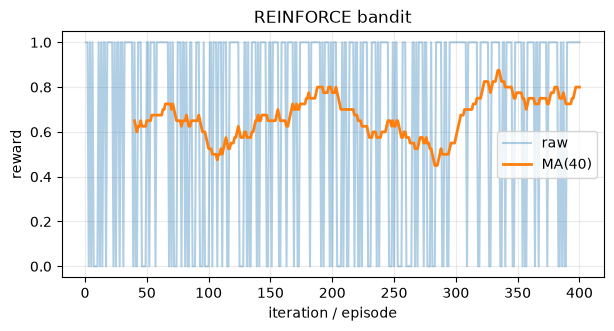

P(best action): 0.876 last-40 reward: 0.8


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(11)
theta, baseline = 0.0, 0.0
rewards, probabilities = [], []
for episode in range(400):
    p = 1 / (1 + np.exp(-theta))
    action = float(rng.random() < p)
    reward = float(rng.random() < (0.25 if action == 0 else 0.75))
    baseline = 0.95 * baseline + 0.05 * reward
    theta += 0.08 * (reward - baseline) * (action - p)
    rewards.append(reward); probabilities.append(p)

plot_curve(rewards, "REINFORCE bandit", "reward", window=40)
print("P(best action):", round(probabilities[-1], 3), "last-40 reward:", np.mean(rewards[-40:]))


### 曲线怎么读

单回合奖励仍是 0/1，真正的学习趋势在移动平均和 `P(best action)`。baseline 不改变期望梯度，却通常让曲线更平稳。

### 调参过程：一次只改变一个因素

- 先不加 baseline 验证梯度方向，再加入 running baseline 比较方差。
- 学习率过小时概率不动，过大时过早饱和；按 3 倍左右尺度试验。
- 最后再调 entropy coefficient，观察探索与收敛速度。

### 失败案例复盘

- 对采样动作使用 `argmax`，失去策略梯度所需探索。
- 忘记 `detach` return/advantage 的目标部分，引入错误梯度路径。
- entropy 符号写反，训练主动变得更确定或更随机。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- advantage 通常要 `.detach()`，否则会出现不期望的二阶耦合。
- 对 batch advantage 做标准化常能稳定训练。
- 不要对概率再手动 `log`；优先使用 `Categorical(logits=...)`。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

记录更新前后三个样本所选动作的概率，验证 advantage 正负与概率变化方向。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

应在更新前保存 `dist.probs.gather(...)`，执行一次优化，再重新前向。正 advantage 样本的所选动作概率通常上升，负 advantage 样本下降；但共享参数会造成样本间耦合，所以不要要求每个样本都严格单调，重点检查总体 loss 方向和单样本隔离测试。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- likelihood-ratio trick 让不可微环境不妨碍策略求梯度。
- 轨迹 log-prob 是各动作 log-prob 之和。
- reward-to-go 和 baseline 都用于降低方差。
- 实现时对 advantage 停止梯度。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**环境转移不可微，为什么 policy gradient 仍能训练？baseline 为什么不能依赖当前采样动作而随意设置？

<details>
<summary>展开答案</summary>

梯度只通过策略的 log-prob 计算，环境只负责提供采样和回报。一般 baseline 需保证相关期望项为零；只依赖状态的 baseline 满足这一性质，任意依赖动作的 baseline 可能引入偏差。
</details>


## 17. 与前后章节连接

第 12 章用 critic 替代整局 Monte Carlo baseline，使策略能以较低方差、更频繁地更新。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

off-policy policy gradient 需要 importance sampling；连续动作常用 Gaussian policy，并对标准差作正值约束。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-11) · [← 学习索引](../README.md)
